# 04 · Figures

This notebook draws the final figures for the paper from the results saved by notebook `03_model`. It does not re-estimate any model.

**Input:** `results/forecasts_expanding_window.csv` and `results/predictor_contributions.csv` from notebook `03_model`.

**Output:** figures in `figures/`.

**Figures:**

1. Out-of-sample forecasts vs actual changes in the metals index.
2. Forecast errors over time: rolling forecast errors of Models A and B, and the cumulative difference between them.
3. Why the GSCPI worsens the forecasts: the GSCPI compared with the range seen in training, and the estimated GSCPI coefficient over time.
4. Out-of-sample contribution of each predictor.

*Code written with help of Claude (Anthropic), asked to guide on how to produce clean code that draws the final figures from the saved results.*

In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from matplotlib.ticker import MultipleLocator, FuncFormatter

RESULTS = Path("../results")
FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)

# saved results from notebook 03
forecasts = pd.read_csv(RESULTS / "forecasts_expanding_window.csv", index_col="date", parse_dates=True)
predictor_contributions = pd.read_csv(RESULTS / "predictor_contributions.csv", index_col="predictor")

# figure settings
CRISIS = ("2020-02", "2023-01")   # supply chain crisis: GSCPI above 1

COLOR_A = "#0072B2"        # Model A (without GSCPI): blue
COLOR_B = "#D55E00"        # Model B (with GSCPI): vermillion (orange-red)
COLOR_ACTUAL = "#999999"   # actual change: grey
COLOR_BETTER = "#56B4E9"   # GSCPI improved the forecast: light blue
COLOR_CRISIS = "#E69F00"   # supply chain crisis shading: orange
CRISIS_ALPHA = 0.15          # transparency of the shading

PREDICTOR_LABELS = {
    "index_worldbank_past_3m": "Momentum",
    "demand_world_12m_lag": "Industrial demand",
    "oil_3m_lag": "Oil price",
    "usd_3m_lag": "US dollar",
    "gscpi_lag": "Supply chain pressure (GSCPI)",
}

print(f"forecasts: {forecasts.index.min():%Y-%m} to {forecasts.index.max():%Y-%m}, "
      f"{len(forecasts)} months, {forecasts['outside training range'].sum()} extrapolation months")

forecasts: 2011-01 to 2026-05, 185 months, 8 extrapolation months


## Figure 1: Forecasts vs actual changes

Out-of-sample forecasts of Models A and B (expanding window) and the actual change in the metals index over the following three months. The dots mark the months in which the GSCPI exceeded all values in the training data.

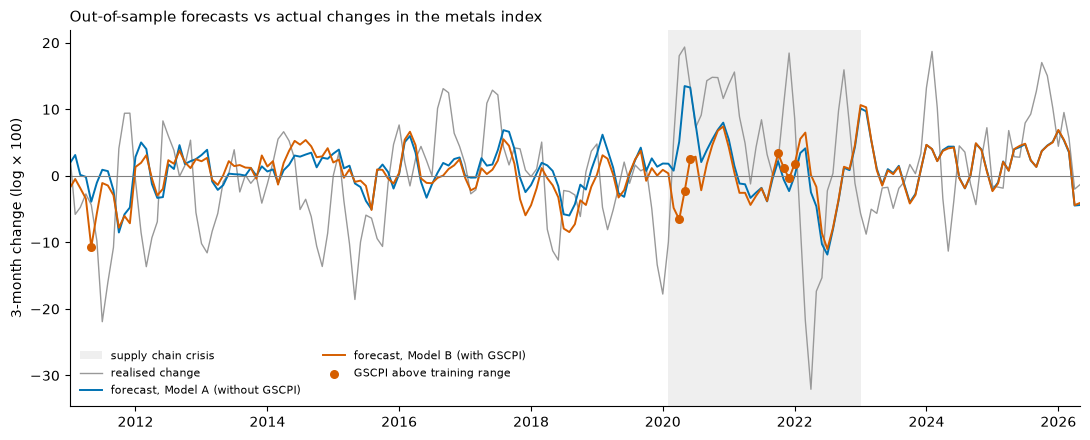

In [21]:
extrapolation = forecasts["outside training range"]

fig, ax = plt.subplots(figsize=(11, 4.5))

# supply chain crisis
ax.axvspan(pd.Timestamp(CRISIS[0]), pd.Timestamp(CRISIS[1]), color="grey", alpha=0.12, linewidth=0,
           label="supply chain crisis")

# actual change and the two forecasts (log × 100)
ax.plot(forecasts.index, 100 * forecasts["actual"], color=COLOR_ACTUAL, linewidth=1,
        label="realised change")
ax.plot(forecasts.index, 100 * forecasts["Model A"], color=COLOR_A, linewidth=1.4,
        label="forecast, Model A (without GSCPI)")
ax.plot(forecasts.index, 100 * forecasts["Model B"], color=COLOR_B, linewidth=1.4,
        label="forecast, Model B (with GSCPI)")

# months in which the GSCPI exceeded all values in the training data
ax.scatter(forecasts.index[extrapolation], 100 * forecasts.loc[extrapolation, "Model B"],
           color=COLOR_B, s=30, zorder=3, label="GSCPI above training range")

ax.axhline(0, color="grey", linewidth=0.8)
ax.set_ylabel("3-month change (log × 100)")
ax.set_title("Out-of-sample forecasts vs actual changes in the metals index", loc="left", fontsize=11)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlim(forecasts.index.min(), forecasts.index.max())
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower left", ncol=2)

fig.tight_layout()
fig.savefig(FIGURES / "forecasts_vs_actual.png", dpi=150)
plt.show()

**Interpretation.** Both models forecast much smaller changes than actually occur and miss the largest movements in metal prices. Outside the supply chain crisis, the forecasts of Models A and B are nearly identical. In spring 2020, when the GSCPI exceeded all earlier values, Model B's forecasts fell below Model A's while metal prices rose sharply, producing its largest errors. In late 2021, the GSCPI moved the forecasts only slightly.

## Figure 2: Forecast errors over time

Top: typical forecast error of Models A and B over the previous 12 months (root mean squared error, log × 100). Bottom: difference between the absolute forecast errors of Model B and Model A in each month with bars above zero indicating that the additon the GSCPI to the model made the forecast worse.

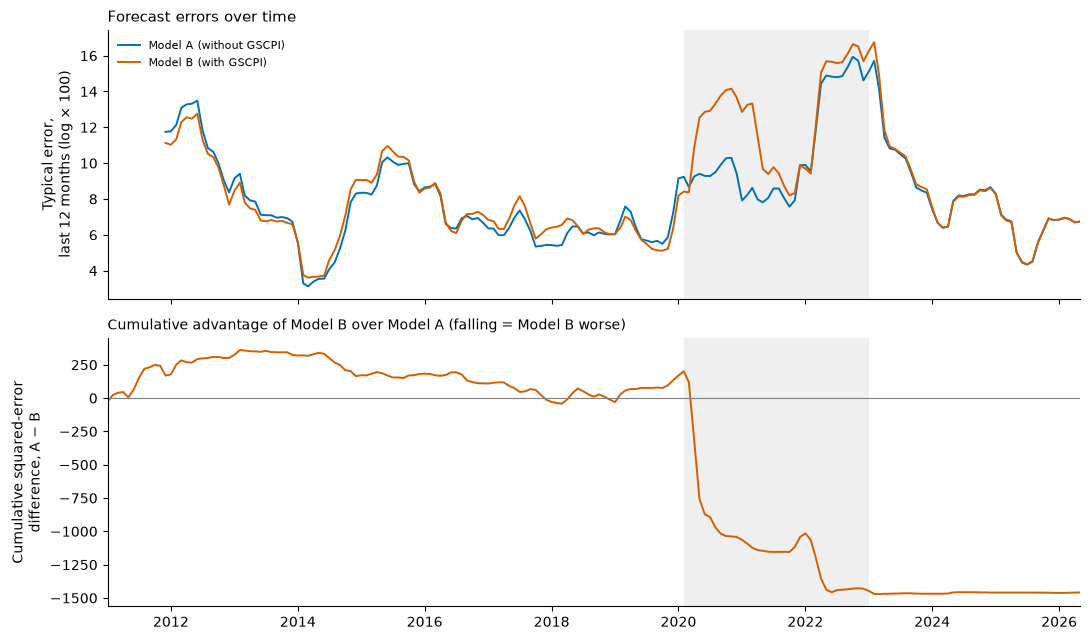

In [10]:
ROLLING_MONTHS = 12

squared_error_a = (forecasts["actual"] - forecasts["Model A"]) ** 2
squared_error_b = (forecasts["actual"] - forecasts["Model B"]) ** 2

# typical error over the previous 12 months (log × 100)
rolling_error_a = 100 * squared_error_a.rolling(ROLLING_MONTHS).mean() ** 0.5
rolling_error_b = 100 * squared_error_b.rolling(ROLLING_MONTHS).mean() ** 0.5

# cumulative advantage of Model B: rises when B forecasts better than A
cumulative_difference = 100**2 * (squared_error_a - squared_error_b).cumsum()

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)

for ax in axes:
    ax.axvspan(pd.Timestamp(CRISIS[0]), pd.Timestamp(CRISIS[1]), color="grey", alpha=0.12, linewidth=0)
    ax.spines[["top", "right"]].set_visible(False)

# top: rolling forecast errors
axes[0].plot(rolling_error_a.index, rolling_error_a, color=COLOR_A, linewidth=1.4,
             label="Model A (without GSCPI)")
axes[0].plot(rolling_error_b.index, rolling_error_b, color=COLOR_B, linewidth=1.4,
             label="Model B (with GSCPI)")
axes[0].set_ylabel("Typical error,\nlast 12 months (log × 100)")
axes[0].set_title("Forecast errors over time", loc="left", fontsize=11)
axes[0].legend(frameon=False, fontsize=8, loc="upper left")

# bottom: cumulative difference
axes[1].plot(cumulative_difference.index, cumulative_difference, color=COLOR_B, linewidth=1.4)
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].set_ylabel("Cumulative squared-error\ndifference, A − B")
axes[1].set_title("Cumulative advantage of Model B over Model A (falling = Model B worse)",
                  loc="left", fontsize=10)

axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[1].set_xlim(forecasts.index.min(), forecasts.index.max())

fig.tight_layout()
fig.savefig(FIGURES / "forecast_errors_over_time.png", dpi=150)
plt.show()

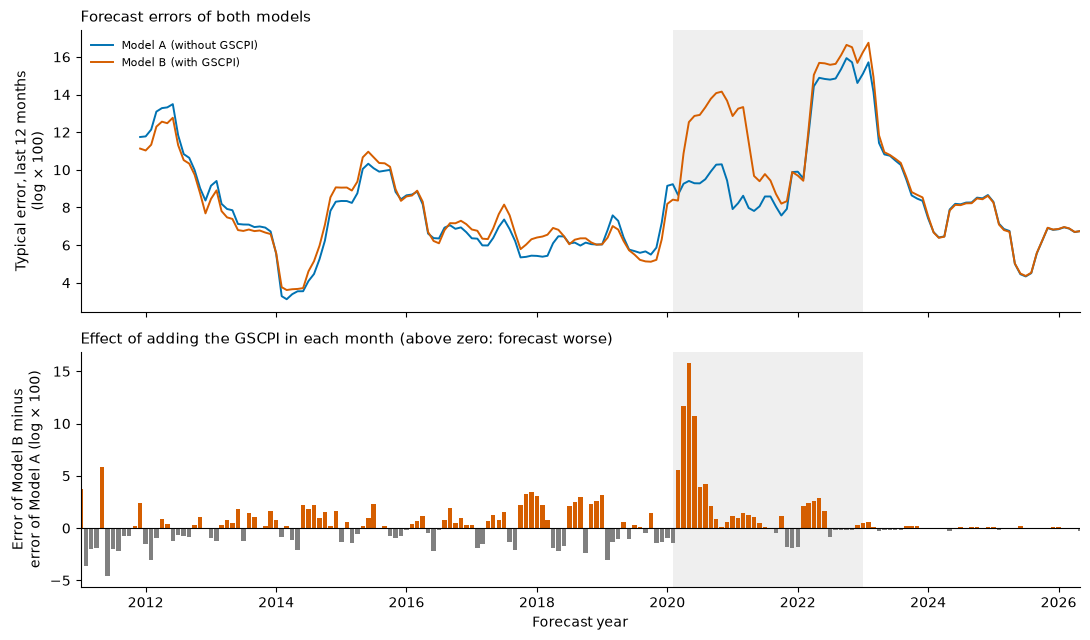

In [14]:
ROLLING_MONTHS = 12

error_a = (forecasts["actual"] - forecasts["Model A"]).abs()
error_b = (forecasts["actual"] - forecasts["Model B"]).abs()

# top: typical error over the previous 12 months (log × 100)
rolling_error_a = 100 * (error_a ** 2).rolling(ROLLING_MONTHS).mean() ** 0.5
rolling_error_b = 100 * (error_b ** 2).rolling(ROLLING_MONTHS).mean() ** 0.5

# bottom: how much more Model B missed than Model A in each month (log × 100)
extra_error_b = 100 * (error_b - error_a)
bar_colors = [COLOR_B if value > 0 else "grey" for value in extra_error_b]

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                         gridspec_kw={"height_ratios": [1.2, 1]})

for ax in axes:
    ax.axvspan(pd.Timestamp(CRISIS[0]), pd.Timestamp(CRISIS[1]), color="grey", alpha=0.12, linewidth=0)
    ax.spines[["top", "right"]].set_visible(False)

# top: typical errors of both models
axes[0].plot(rolling_error_a.index, rolling_error_a, color=COLOR_A, linewidth=1.4,
             label="Model A (without GSCPI)")
axes[0].plot(rolling_error_b.index, rolling_error_b, color=COLOR_B, linewidth=1.4,
             label="Model B (with GSCPI)")
axes[0].set_ylabel("Typical error, last 12 months\n(log × 100)")
axes[0].set_title("Forecast errors of both models", loc="left", fontsize=11)
axes[0].legend(frameon=False, fontsize=8, loc="upper left")

# bottom: monthly effect of adding the GSCPI
axes[1].bar(extra_error_b.index, extra_error_b, width=25, color=bar_colors)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Error of Model B minus\nerror of Model A (log × 100)")
axes[1].set_xlabel("Forecast year")
axes[1].set_title("Effect of adding the GSCPI in each month (above zero: forecast worse)",
                  loc="left", fontsize=11)

axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[1].set_xlim(forecasts.index.min(), forecasts.index.max())

fig.tight_layout()
fig.savefig(FIGURES / "forecast_errors_over_time.png", dpi=150)
plt.show()

**Interpretation.** Forecast errors of both models rise and fall together with market turbulence. In most months, adding the GSCPI changes the forecast error by less than about 3 log points, in either direction. The clear exception is the start of 2020, when Model B missed by up to 16 log points more than Model A, smaller losses also occur in 2018 and 2022. These few months account for most of Model B's out-of-sample loss.

## Figure 3: Why does the GSCPI worsen the forecasts

Top: the GSCPI at each forecast date and the highest value in the corresponding training data, the dots mark the months in which the model had to extrapolate. Bottom: the GSCPI coefficient of Model B, estimated with the data available at each forecast date.

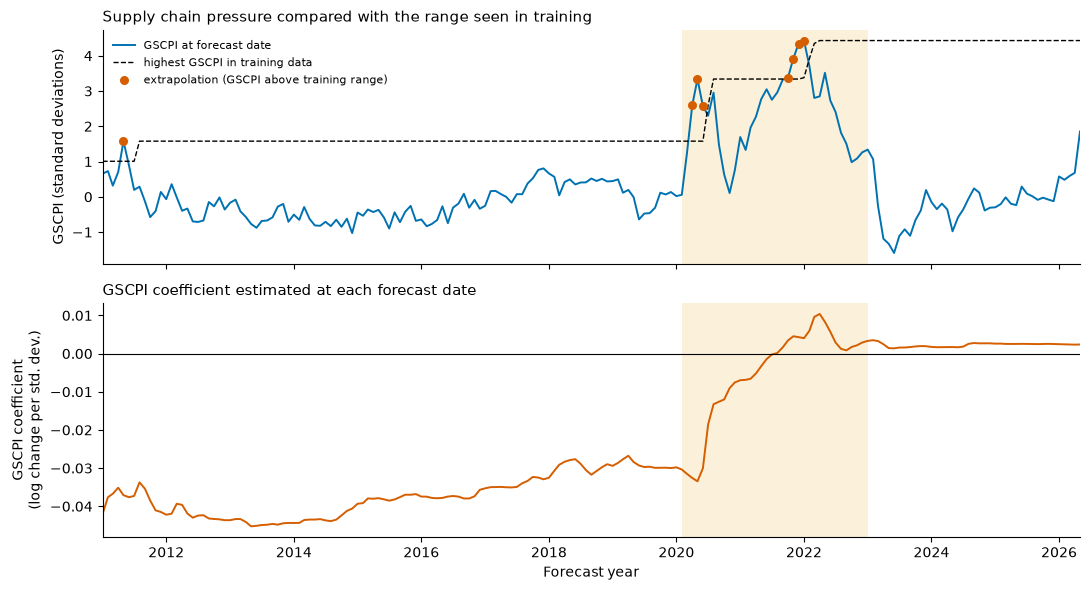

In [17]:
extrapolation = forecasts["outside training range"]

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

for ax in axes:
    ax.axvspan(pd.Timestamp(CRISIS[0]), pd.Timestamp(CRISIS[1]), color=COLOR_CRISIS, alpha=CRISIS_ALPHA,
               linewidth=0)
    ax.spines[["top", "right"]].set_visible(False)

# top: GSCPI vs the range seen in training
axes[0].plot(forecasts.index, forecasts["GSCPI"], color=COLOR_A, linewidth=1.4,
             label="GSCPI at forecast date")
axes[0].plot(forecasts.index, forecasts["highest GSCPI in training"], color="black", linewidth=1,
             linestyle="--", label="highest GSCPI in training data")
axes[0].scatter(forecasts.index[extrapolation], forecasts.loc[extrapolation, "GSCPI"],
                color=COLOR_B, s=30, zorder=3, label="extrapolation (GSCPI above training range)")
axes[0].set_ylabel("GSCPI (standard deviations)")
axes[0].set_title("Supply chain pressure compared with the range seen in training", loc="left", fontsize=11)
axes[0].legend(frameon=False, fontsize=8, loc="upper left")

# bottom: GSCPI coefficient estimated at each forecast date
axes[1].plot(forecasts.index, forecasts["GSCPI coefficient"], color=COLOR_B, linewidth=1.4)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("GSCPI coefficient\n(log change per std. dev.)")
axes[1].set_xlabel("Forecast year")
axes[1].set_title("GSCPI coefficient estimated at each forecast date",
                  loc="left", fontsize=11)

axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[1].set_xlim(forecasts.index.min(), forecasts.index.max())

fig.tight_layout()
fig.savefig(FIGURES / "gscpi_extrapolation.png", dpi=150)
plt.show()

In [19]:
spring_2020 = forecasts.loc["2020-04":"2020-06"]

spring_2020_table = pd.DataFrame({
    "realised change": 100 * spring_2020["actual"],
    "forecast, Model A": 100 * spring_2020["Model A"],
    "forecast, Model B": 100 * spring_2020["Model B"],
    "GSCPI effect (B − A)": 100 * (spring_2020["Model B"] - spring_2020["Model A"]),
})
spring_2020_table.index = spring_2020_table.index.strftime("%Y-%m")
spring_2020_table.round(1)

,realised change,"forecast, Model A","forecast, Model B",GSCPI effect (B − A)
date,,,,
2020-04,18.0,5.1,-6.6,-11.7
2020-05,19.4,13.5,-2.3,-15.8
2020-06,13.4,13.3,2.5,-10.7


**Interpretation.** The figure links the out-of-sample losses of Model B (notebook 03) to two features of the recursively estimated GSCPI effect. First, before 2020 the GSCPI remained within a narrow range, therefore the realised values in the beginnging of the year of 2020 and late 2021 lay outside the support of the training data, and the forecasts required extrapolation (top panel). Second, the expanding-window estimate of the GSCPI coefficient remained negative until 2020 (about −0.03 to −0.04) and reversed sign only after the 2020 observations entered the estimation sample (bottom panel), indicating parameter instability. In April–June 2020, the combination of a negative coefficient and record GSCPI values lowered Model B's forecasts by 10.7 to 15.8 log points relative to Model A, while the realised three-month changes in the metals index were +13.4 to +19.4 log points. The coefficient adjusted only after these observations had been realised, so it could not improve the forecasts in the months concerned. Consequently, Model B's losses are concentrated in the supply chain crisis ($R^2_{OOS}$ of −34.6% relative to Model A) and are negligible in the remaining months (+1.7%).

## Figure 4: Contribution of each predictor

Out-of-sample gain from adding each predictor (expanding window): for the controls, Model A compared with Model A without that predictor; for the GSCPI, Model B compared with Model A. Positive values mean the predictor reduces the squared forecast errors. Bars marked with an asterisk are significant at the 5% level (Clark-West test).

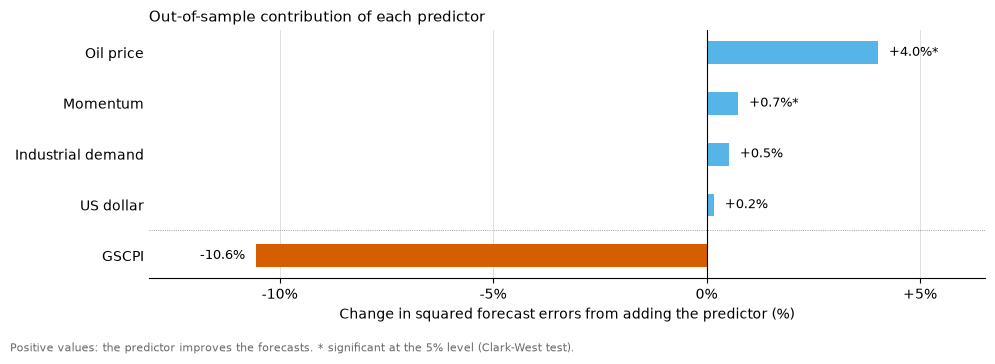

In [ ]:
labels = PREDICTOR_LABELS | {"gscpi_lag": "GSCPI"}   # short label for the GSCPI in this figure

contributions = predictor_contributions.copy()
contributions.index = [labels[predictor] for predictor in contributions.index]

# controls sorted by gain, GSCPI at the bottom as its own group
controls = contributions.drop("GSCPI").sort_values("gain from adding it (%)")
ordered = pd.concat([contributions.loc[["GSCPI"]], controls])

gains = ordered["gain from adding it (%)"]
p_values = ordered["Clark-West p"]
bar_colors = [COLOR_B if label == "GSCPI" else COLOR_BETTER for label in ordered.index]

fig, ax = plt.subplots(figsize=(10, 3.6))

ax.barh(ordered.index, gains, color=bar_colors, height=0.45, zorder=2)
ax.axvline(0, color="black", linewidth=0.8, zorder=3)
ax.axhline(0.5, color="grey", linewidth=0.6, linestyle=":")   # separates GSCPI from the controls
ax.grid(axis="x", color="lightgrey", linewidth=0.5, zorder=0)

# value labels next to each bar, asterisk if significant at 5% (Clark-West)
for position, (gain, p_value) in enumerate(zip(gains, p_values)):
    label = f"{gain:+.1f}%" + ("*" if p_value < 0.05 else "")
    ax.text(gain + (0.25 if gain >= 0 else -0.25), position, label, va="center",
            ha="left" if gain >= 0 else "right", fontsize=9)

# x-axis: ticks every 5 percentage points, shown as percentages
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:+.0f}%" if value else "0%"))
ax.set_xlim(gains.min() - 2.5, gains.max() + 2.5)
ax.set_xlabel("Change in squared forecast errors from adding the predictor (%)")

ax.set_title("Out-of-sample contribution of each predictor", loc="left", fontsize=11)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.text(0.01, 0.01, "Positive values: the predictor improves the forecasts. "
                     "* significant at the 5% level (Clark-West test).",
         ha="left", fontsize=8, color="dimgrey")

fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIGURES / "predictor_contributions.png", dpi=150)
plt.show()

## Figure 6: Shape of the GSCPI effect, Gaussian process vs linear model

Predicted change in the metals index across GSCPI values, other predictors held at their means: GP B with its 90% predictive interval, compared with linear Model B. Dots show realised changes. In-sample fit, so illustrative only.

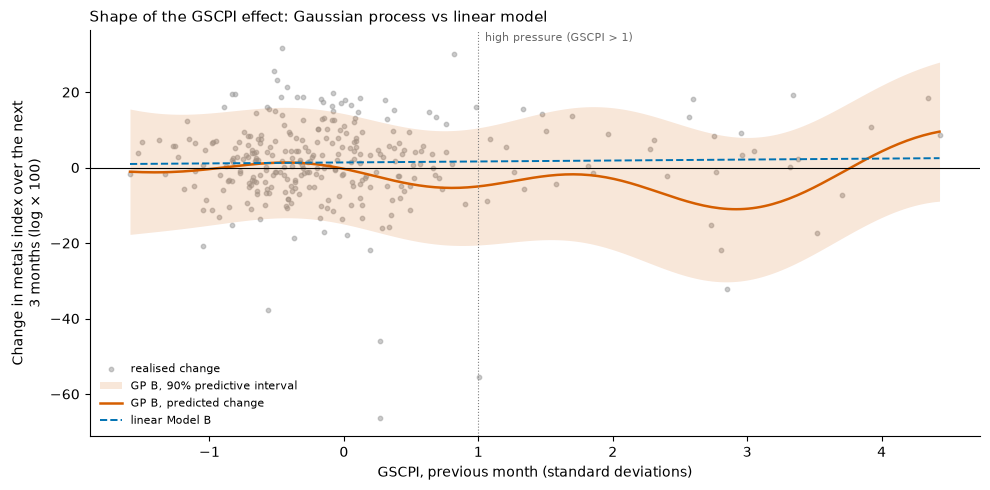

In [29]:
gscpi_effect = pd.read_csv(RESULTS / "gp_gscpi_effect.csv")
analysis = pd.read_csv(Path("../data/processed") / "analysis_dataset.csv", index_col="date", parse_dates=True)
Z_90 = 1.645   # 90% interval: ±1.645 standard deviations

fig, ax = plt.subplots(figsize=(10, 5))

# realised changes (all months)
ax.scatter(analysis["gscpi_lag"], 100 * analysis["index_worldbank_next_3m"], s=10,
           color=COLOR_ACTUAL, alpha=0.5, label="realised change", zorder=1)

# GP B: mean and 90% predictive interval
ax.fill_between(gscpi_effect["GSCPI"],
                100 * (gscpi_effect["GP B mean"] - Z_90 * gscpi_effect["GP B std"]),
                100 * (gscpi_effect["GP B mean"] + Z_90 * gscpi_effect["GP B std"]),
                color=COLOR_B, alpha=0.15, linewidth=0, label="GP B, 90% predictive interval")
ax.plot(gscpi_effect["GSCPI"], 100 * gscpi_effect["GP B mean"], color=COLOR_B, linewidth=1.8,
        label="GP B, predicted change")

# linear Model B
ax.plot(gscpi_effect["GSCPI"], 100 * gscpi_effect["linear Model B"], color=COLOR_A, linewidth=1.4,
        linestyle="--", label="linear Model B")

ax.axvline(1, color="grey", linewidth=0.8, linestyle=":")   # high-pressure threshold
ax.text(1.05, ax.get_ylim()[1] * 0.92, "high pressure (GSCPI > 1)", fontsize=8, color="dimgrey")
ax.axhline(0, color="black", linewidth=0.8)

ax.set_xlabel("GSCPI, previous month (standard deviations)")
ax.set_ylabel("Change in metals index over the next\n3 months (log × 100)")
ax.set_title("Shape of the GSCPI effect: Gaussian process vs linear model", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower left")

fig.tight_layout()
fig.savefig(FIGURES / "gp_gscpi_effect.png", dpi=150)
plt.show()

**Interpretation.** Where most observations lie (GSCPI below 1), the GP predicts essentially no effect, similarly to the linear model. At higher GSCPI values, which is covered by few observations, the GP curve bends, but it stays well within its 90% predictive interval, which contains the linear prediction throughout. Combined with GP B's poor out-of-sample performance, the figure provides no reliable evidence of a nonlinear GSCPI effect.